# Baseline 2: a single multi-output XGBoost tree

Follows on from `baseline_xgboost.ipynb` (14 independent per-unit models, overall micro-AUC
0.647). Discussion in the project log (`report/log/005_next_steps_discussion.tex`) concluded the
Tokke/Vinje weakness in that baseline is more likely a correlated-*output* problem than a
missing-*input* problem, since every unit's model already saw all 17 reservoirs' data. This
notebook tests that directly: **one XGBoost model, trained on all 14 targets jointly**, using
`multi_strategy="multi_output_tree"` (each leaf stores a vector of 14 probabilities, split
choices optimized jointly across units) instead of 14 separate single-output trees.

To isolate the effect of *joint vs. independent* modeling specifically, everything else is held
fixed and identical to baseline 1: same 54 raw features, same hyperparameters, same
chronological split (train 2015–2021, validate on held-out 2022), same official metric.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../..")
from kaggle_metric import score as kaggle_score

INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE_COLOR,
    "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "grid.color": GRID,
    "axes.grid": True, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 11, "figure.dpi": 110,
})


## 1. Load, split (identical protocol to baseline 1)

In [2]:
train_df = pd.read_parquet("../../data/processed/train_hourly.parquet")
train_df["year"] = train_df["starttime"].dt.year

target_cols = [c for c in train_df.columns if c.startswith("on_")]
units = [c[len("on_"):] for c in target_cols]
feature_cols = [c for c in train_df.columns
                if c not in ("run_no", "split", "starttime", "timestamp", "year") and c not in target_cols]

is_val = train_df["year"] == 2022
fit_df, val_df = train_df[~is_val], train_df[is_val]

X_fit, X_val = fit_df[feature_cols], val_df[feature_cols]
Y_fit = fit_df[target_cols].astype(int)

print(f"fit  rows: {len(fit_df):,}   val rows: {len(val_df):,}")


fit  rows: 429,576   val rows: 61,320


## 2. Train one multi-output model

In [3]:
model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", multi_strategy="multi_output_tree",
    objective="binary:logistic", eval_metric="logloss", n_jobs=-1, random_state=0,
)
model.fit(X_fit, Y_fit)

val_proba = model.predict_proba(X_val)  # shape (n_val_rows, 14)
print("predict_proba shape:", val_proba.shape)


predict_proba shape: (61320, 14)


## 3. Score with the competition's own metric

In [4]:
val_pred = pd.DataFrame({"run_no": val_df["run_no"].values, "hour": val_df["hour"].values})
for i, u in enumerate(units):
    val_pred[f"pred_{u}"] = val_proba[:, i]

wide_frames = []
for u in units:
    piv = val_pred.pivot(index="run_no", columns="hour", values=f"pred_{u}")
    piv.columns = [f"result_committed_{u}_t{h}" for h in piv.columns]
    wide_frames.append(piv)
submission_val = pd.concat(wide_frames, axis=1).reset_index().rename(columns={"run_no": "Run No"})

uc = pd.read_csv("../../data/kernel/Unit_commitment_decisions.csv")
solution_val = uc[uc["Run No"].isin(val_df["run_no"].unique())]

overall_auc = kaggle_score(solution_val, submission_val)
print(f"Overall micro-average ROC-AUC (2022 validation, competition metric): {overall_auc:.4f}")
print(f"Baseline 1 (14 independent models) was: 0.6473")


Overall micro-average ROC-AUC (2022 validation, competition metric): 0.6870
Baseline 1 (14 independent models) was: 0.6473


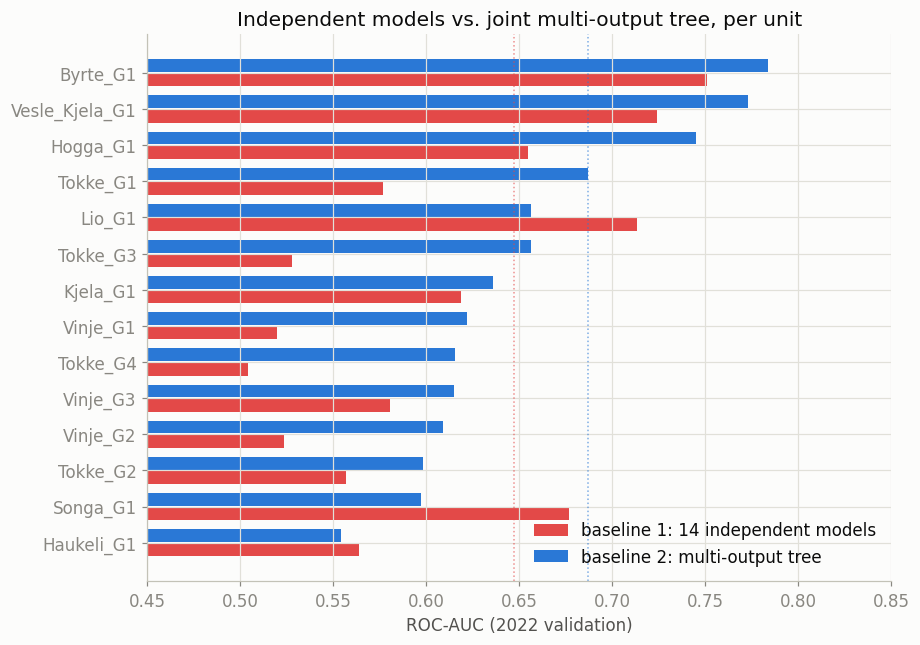

,baseline1_independent,baseline2_multioutput,delta
Songa_G1,0.676782,0.597126,-0.079656
Lio_G1,0.713363,0.656275,-0.057088
Haukeli_G1,0.563680,0.554092,-0.009588
Kjela_G1,0.618756,0.636079,0.017323
Byrte_G1,0.750969,0.783808,0.032839
Vinje_G3,0.580332,0.614952,0.034620
Tokke_G2,0.556981,0.597956,0.040975
Vesle_Kjela_G1,0.723788,0.773226,0.049438
Vinje_G2,0.523580,0.608859,0.085279
Hogga_G1,0.654844,0.744761,0.089917


In [5]:
per_unit_auc = pd.Series({
    u: roc_auc_score(val_df[f"on_{u}"], val_pred[f"pred_{u}"])
    for u in units
}).sort_values()

# baseline 1's per-unit numbers, hard-coded from report/leaderboard.md / log entry 004,
# for a direct side-by-side comparison
baseline1_auc = pd.Series({
    "Byrte_G1": 0.750969, "Vesle_Kjela_G1": 0.723788, "Lio_G1": 0.713363, "Songa_G1": 0.676782,
    "Hogga_G1": 0.654844, "Kjela_G1": 0.618756, "Vinje_G3": 0.580332, "Tokke_G1": 0.576513,
    "Haukeli_G1": 0.563680, "Tokke_G2": 0.556981, "Tokke_G3": 0.527619, "Vinje_G2": 0.523580,
    "Vinje_G1": 0.519480, "Tokke_G4": 0.503888,
}).reindex(per_unit_auc.index)

fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(per_unit_auc))
ax.barh(y - 0.2, baseline1_auc.values, height=0.35, color=CAT[7], label="baseline 1: 14 independent models")
ax.barh(y + 0.2, per_unit_auc.values, height=0.35, color=CAT[0], label="baseline 2: multi-output tree")
ax.axvline(0.6473, color=CAT[7], lw=1, ls=":", alpha=0.6)
ax.axvline(overall_auc, color=CAT[0], lw=1, ls=":", alpha=0.6)
ax.set_yticks(y, per_unit_auc.index)
ax.set_xlim(0.45, 0.85)
ax.set_xlabel("ROC-AUC (2022 validation)")
ax.set_title("Independent models vs. joint multi-output tree, per unit")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({"baseline1_independent": baseline1_auc, "baseline2_multioutput": per_unit_auc,
                            "delta": per_unit_auc - baseline1_auc}).sort_values("delta")
comparison


## 4. Feature importance for the joint model

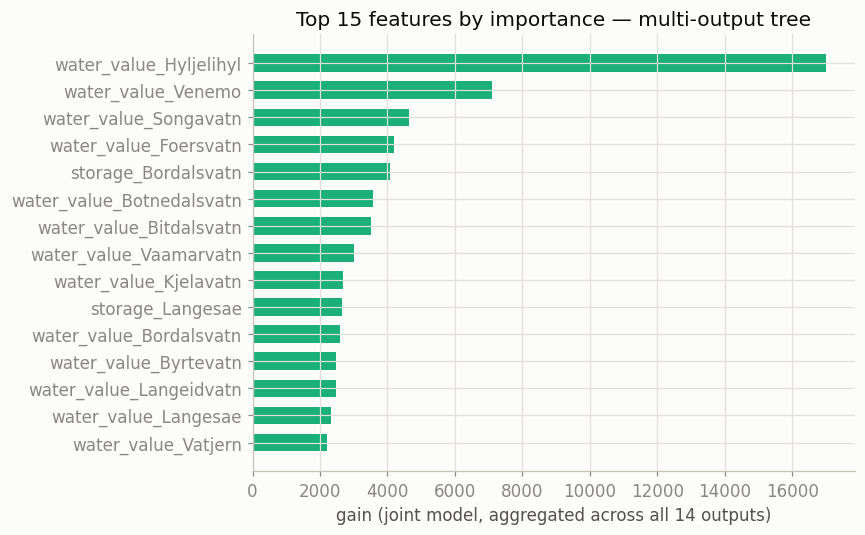

In [6]:
imp = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color=CAT[2], height=0.65)
ax.set_xlabel("gain (joint model, aggregated across all 14 outputs)")
ax.set_title("Top 15 features by importance — multi-output tree")
plt.tight_layout()
plt.show()


## 5. Where this leaves us

Same protocol, same features, same hyperparameters as baseline 1 — the only change is
independent-per-unit vs. joint multi-output trees, so the delta above is a real read on whether
sharing structure across units helps, not a confound from anything else changing at the same
time. Logged in `report/log/006_multioutput_tree_baseline.tex` and
`report/leaderboard.md`.
